# Part A v2: What is a hit, once money counts?

v1 defined a hit from the audience's point of view only (rating × votes). A studio greenlighting a AAA title also needs the film to **make money**. v2 adds that, and builds the hit list **by year** and **all time**.

**What changed from v1**

| | v1 | v2 |
|---|---|---|
| Data | IMDb (+ MovieLens) | + **TMDB** budget, revenue and plot text (joined on `imdb_id`), + optional **CPI** |
| Hit definition | audience only | **two-stage gate**: audience hit **and** commercial hit (ROI × box office, plus break-even) |
| Methods | KMeans, DBSCAN, median split | + **HDBSCAN** (GLOSH outlier score) and **Isolation Forest**: five voters |
| Comparing eras | votes vs. same year | **every** axis vs. same-year films (also cancels inflation) |
| Output | one hit label | verdicts, **hits by year**, **all-time hits**, budget-tier and genre economics |

**Map to the brief**

| Question from the brief | Section |
|---|---|
| Highest rated movie of 2023, balancing ratings and votes | 2 |
| Most popular actor of 2023 | 2 |
| Define a metric for a "hit movie", justified for a studio | 3 to 9 |
| Trends in user-movie preferences over the years | 9 to 11 |

**First time?** Set `DEMO = True` to run on synthetic data in about a minute (it checks your setup; its numbers are fake, never put them in the deck). The one-command version of this notebook is `python scripts/run_part_a_v2.py`.

## 1. Setup and data

In [3]:
DEMO = False  # True = small synthetic data, for checking your setup only

import logging, sys
from dataclasses import replace
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

# Find the project root (the folder containing src/nextaaa), wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "nextaaa").exists())
sys.path.insert(0, str(ROOT / "src"))

from nextaaa import (ensemble, finance, hits, io_imdb, io_tmdb, movielens, plots, plots_v2,
                     popularity, ratings, trends)
from nextaaa.config import AnalysisConfig, Paths
from nextaaa.pipeline_v2 import v2_paths

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s", force=True)
logging.getLogger("nextaaa.clustering").setLevel(logging.WARNING)  # quieter KMeans loop
pd.set_option("display.max_columns", 40, "display.width", 180, "display.float_format", "{:,.2f}".format)

In [4]:
cfg = AnalysisConfig()  # every tunable number, documented in src/nextaaa/config.py

if DEMO:
    from nextaaa.synthetic import (make_synthetic_cpi, make_synthetic_imdb, make_synthetic_movielens,
                                   make_synthetic_tmdb)
    demo = ROOT / "data" / "synthetic"
    if not (demo / "imdb" / "title.basics.tsv.gz").exists():
        make_synthetic_imdb(demo / "imdb"); make_synthetic_movielens(demo / "imdb", demo / "ml-20m")
    if not (demo / "tmdb").exists():
        make_synthetic_tmdb(demo / "imdb", demo / "tmdb"); make_synthetic_cpi(demo / "cpi")
    paths = Paths.resolve(demo / "imdb", demo / "ml-20m", demo / "cache", ROOT / "outputs_demo",
                          demo / "tmdb", demo / "cpi")
    cfg = replace(cfg, min_votes_for_clustering=200, movielens_min_ratings_per_year=500,
                  movielens_min_ratings_for_std=20, dbscan_min_samples=10)
else:
    # Defaults: data/imdb, data/ml-20m, data/tmdb, data/cpi (or NEXTAAA_* env vars)
    paths = Paths.resolve()

out = v2_paths(paths)          # v2 writes to outputs/v2/, leaving v1's outputs alone
out.make_output_dirs()
FIG, TAB = out.figures_dir, out.tables_dir
def save(fig, name):
    plots.save(fig, FIG / f"{name}.png"); return fig
paths

Paths(imdb_dir=WindowsPath('C:/Users/user/Documents/next-aaa-title-part-a/next-aaa-title/data/imdb'), movielens_dir=WindowsPath('C:/Users/user/Documents/next-aaa-title-part-a/next-aaa-title/data/ml-20m'), cache_dir=WindowsPath('C:/Users/user/Documents/next-aaa-title-part-a/next-aaa-title/data/cache'), output_dir=WindowsPath('C:/Users/user/Documents/next-aaa-title-part-a/next-aaa-title/outputs'), tmdb_dir=WindowsPath('C:/Users/user/Documents/next-aaa-title-part-a/next-aaa-title/data/tmdb'), cpi_dir=WindowsPath('C:/Users/user/Documents/next-aaa-title-part-a/next-aaa-title/data/cpi'))

### 1.1 IMDb (required)
Same loader as v1: streams the big files, keeps feature films, caches the result.

In [6]:
movies = io_imdb.load_movies(paths, cfg)
print(f"{len(movies):,} rated feature films")

INFO nextaaa._cache: Cache hit: title_basics__e914106aea.parquet
INFO nextaaa._cache: Cache hit: title_ratings__noparams.parquet
INFO nextaaa.io_imdb: Movie table: 327,437 rated feature films


327,437 rated feature films


### 1.2 TMDB: budget, revenue and plot text (optional but central to v2)

Put the Kaggle download (`archive.zip`, untouched) or the extracted CSV in `data/tmdb/`. The loader joins on `imdb_id` = IMDb's `tconst`, and handles this dataset's known problems:

| Problem in the raw file | What we do |
|---|---|
| Unknown budget/revenue stored as **0** (most films) | treated as missing |
| Figures typed **in millions** ("5" meaning $5M) | below $10k → missing (real micro-budgets like *Paranormal Activity*, ~$15k, survive) |
| Revenue **copied from budget** | revenue → missing |
| **Duplicate** `imdb_id`s | keep the row with the most information |
| Missing / malformed `imdb_id` | cannot be joined, dropped |
| Plot text with commas, quotes, line breaks | handled by the CSV parser |

The report below is worth an appendix slide: it tells the data scientists exactly how much money data survived and why.

In [8]:
tmdb, tmdb_report = io_tmdb.load_tmdb(paths, cfg, set(movies["tconst"]))
pd.Series(tmdb_report, name="count").to_frame()

INFO nextaaa._cache: Cache hit: tmdb_clean__38170ac020.parquet
INFO nextaaa.io_tmdb: TMDB: 269,770 films joined, 9,444 with both budget and revenue


,count
available,True
source,TMDB_movie_dataset_v11.csv
rows_read,1526586
rows_matching_imdb_films,271028
rows_without_valid_imdb_id,0
budget_zero_or_missing,247760
revenue_zero_or_missing,255265
budget_below_floor,2889
revenue_below_floor,901
revenue_equal_to_budget,102


### 1.3 CPI (optional)

Download US CPI from FRED ([CPIAUCSL](https://fred.stlouisfed.org/series/CPIAUCSL) → Download → CSV) into `data/cpi/`. It is used only to **show** 2023 dollars and to define the AAA-scale budget tier consistently across decades. The clustering does not need it, because every money figure is compared with same-year films (section 4), and ROI is a same-year ratio, so inflation cancels.

In [10]:
cpi = finance.load_cpi(paths)
print("CPI available:", cpi is not None)

INFO nextaaa.finance: CPI loaded from CPIAUCSL.csv: 1947-2026


CPI available: True


## 2. The 2023 questions

### 2.1 Highest rated film of 2023 (unchanged from v1, now with money columns)

The ranking still uses the **shrunk rating** (IMDb's Bayesian Top-250 formula), $\text{shrunk} = \frac{v}{v+m}R + \frac{m}{v+m}C$. Budget, revenue and ROI are added as context: a studio will ask "and did it make money?".

In [12]:
year = cfg.target_year
board, info = ratings.top_rated(movies, year, cfg.shrinkage_quantile, cfg.min_votes_target_year, top_n=15)
if tmdb is not None:
    board = board.merge(tmdb[["tconst", "budget", "revenue"]], on="tconst", how="left")
    board["roi_multiple"] = board["revenue"] / board["budget"]
board.to_csv(TAB / f"top_rated_{year}.csv", index=False)
print(f"m = {info['m']:,.0f} votes, C = {info['C']:.2f}, pool = {info['pool_size']:,} films")
board

m = 6,163 votes, C = 5.81, pool = 5,197 films


,rank_shrunk,primaryTitle,averageRating,numVotes,shrunk_rating,rank_raw,genres,tconst,budget,revenue,roi_multiple
0,1,12th Fail,8.70,179116,8.60,59,"Biography,Drama",tt23849204,NaN,NaN,NaN
1,2,Spider-Man: Across the Spider-Verse,8.50,560025,8.47,88,"Action,Adventure,Animation",tt9362722,"100,000,000.00","683,241,751.00",6.83
2,3,20 Days in Mariupol,8.60,65995,8.36,70,"Documentary,War",tt24082438,NaN,NaN,NaN
3,4,Oppenheimer,8.20,1108296,8.19,148,"Biography,Drama,History",tt15398776,"100,000,000.00","933,700,000.00",9.34
4,5,Lost Ladies,8.30,62679,8.08,130,"Comedy,Drama",tt21626284,NaN,NaN,NaN
5,6,Guardians of the Galaxy Vol. 3,7.90,492024,7.87,229,"Action,Adventure,Comedy",tt6791350,"250,000,000.00","845,430,302.00",3.38
6,7,The Holdovers,7.90,275587,7.85,229,"Comedy,Drama",tt14849194,NaN,NaN,NaN
7,8,Hi Nanna,8.30,27817,7.85,130,"Drama,Family,Romance",tt25433734,NaN,NaN,NaN
8,9,Perfect Days,7.90,114001,7.79,229,Drama,tt27503384,NaN,NaN,NaN
9,10,Past Lives,7.80,179505,7.73,277,"Drama,Romance",tt13238346,NaN,"6,000,000.00",NaN


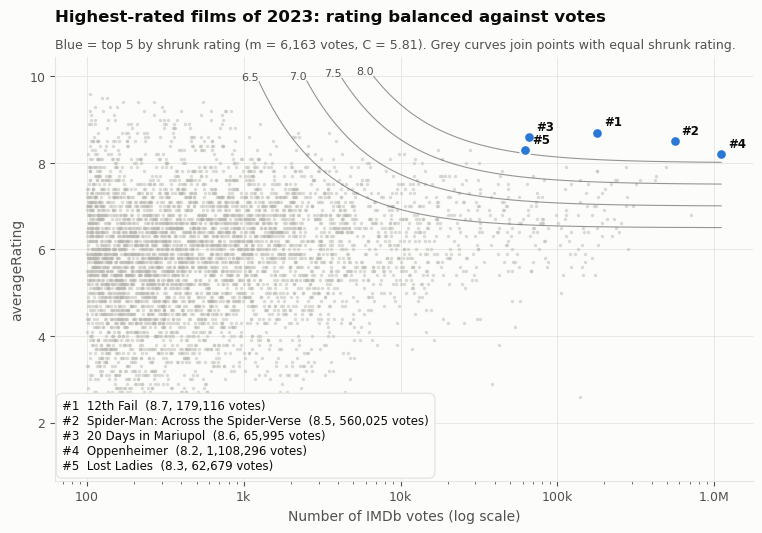

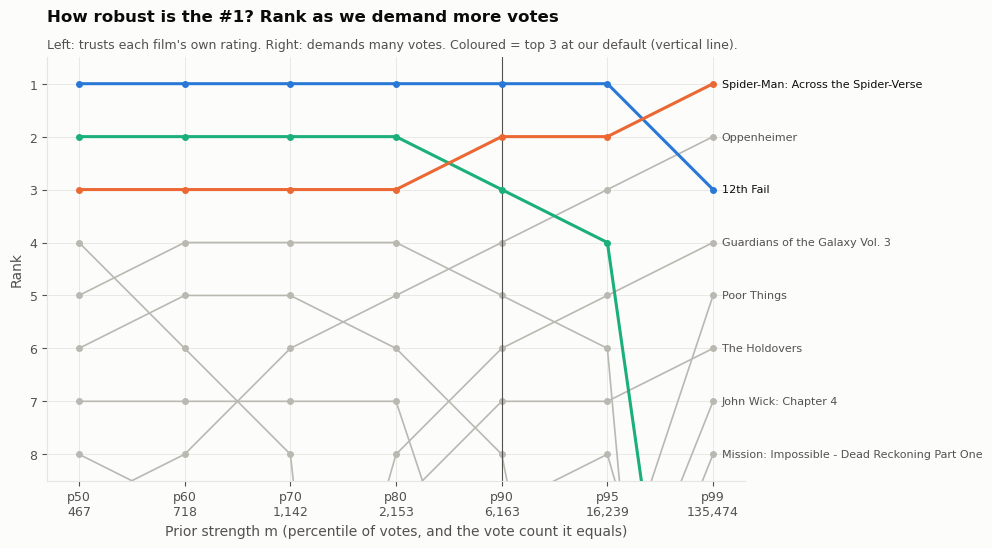

In [13]:
sens = ratings.sensitivity_to_m(movies, year, cfg.sensitivity_quantiles, cfg.min_votes_target_year)
display(save(plots.plot_rating_vs_votes(movies, info, board), f"01_rating_vs_votes_{year}"))
display(save(plots.plot_m_sensitivity(sens, cfg.shrinkage_quantile), f"02_m_sensitivity_{year}"))

### 2.2 Most popular actor of 2023: now three definitions

With TMDB revenue we can add the definition that was parked in v1:

- **Reach** = Σ billing weight × votes: *who brings an audience?*
- **Net goodwill** = Σ billing weight × votes × (shrunk rating − 2023 average): *who brings an audience that likes the film?*
- **Box office** = Σ billing weight × worldwide revenue: *whose films sold tickets?* Only films with known revenue count, so say on the slide that this under-counts actors in smaller films.

Billing weight = $1/\sqrt{\text{rank}}$ (lead 1.00, 4th billed 0.50).

In [15]:
credits = io_imdb.load_actor_credits(paths, cfg, set(movies["tconst"]))
year_ids = set(movies.loc[movies["startYear"] == year, "tconst"])
names = io_imdb.load_names(paths, set(credits.loc[credits["tconst"].isin(year_ids), "nconst"]))
pop = popularity.actor_popularity(movies, credits, names, year, cfg.shrinkage_quantile,
                                  cfg.billing_weight_power, cfg.min_votes_target_year)
box = None
if tmdb is not None:
    films_money = movies.merge(tmdb[["tconst", "revenue"]], on="tconst", how="left")
    box = popularity.actor_box_office(films_money, credits, names, year, cfg.billing_weight_power)
popularity.three_way(pop, box, top_n=10)

INFO nextaaa._cache: Cache hit: actor_credits__3ad3a72935.parquet
INFO nextaaa._cache: Cache hit: names__fd57c5653b.parquet


,Reach: actor,Reach: weighted votes,Reach: top film,Goodwill: actor,Goodwill: score,Goodwill: top film,Box office: actor,Box office: weighted US$,Box office: top film
rank,,,,,,,,,
1,Cillian Murphy,"1,110,247.00",Oppenheimer,Cillian Murphy,"2,629,464.97",Oppenheimer,Chris Pratt,"2,201,155,565.00",The Super Mario Bros. Movie
2,Emily Blunt,"840,426.62",Oppenheimer,Emily Blunt,"1,899,145.14",Oppenheimer,Margot Robbie,"1,428,545,028.00",Barbie
3,Matt Damon,"840,043.99",Oppenheimer,Matt Damon,"1,825,670.29",Oppenheimer,Issa Rae,"1,066,333,294.13",Barbie
4,Chris Pratt,"796,124.77",Guardians of the Galaxy Vol. 3,Shameik Moore,"1,487,444.02",Spider-Man: Across the Spider-Verse,Vin Diesel,"1,024,252,278.56",Guardians of the Galaxy Vol. 3
5,Margot Robbie,"709,508.00",Barbie,Chris Pratt,"1,366,463.37",Guardians of the Galaxy Vol. 3,Ryan Gosling,"1,010,133,876.53",Barbie
6,Alden Ehrenreich,"621,036.28",Oppenheimer,Robert Downey Jr.,"1,314,477.93",Oppenheimer,Anya Taylor-Joy,"958,642,526.89",The Super Mario Bros. Movie
7,Issa Rae,"607,633.37",Barbie,Alden Ehrenreich,"1,200,760.07",Oppenheimer,Cillian Murphy,"933,700,000.00",Oppenheimer
8,Shameik Moore,"560,025.00",Spider-Man: Across the Spider-Verse,Scott Grimes,"1,073,266.73",Oppenheimer,Jing Wu,"894,622,827.36",The Wandering Earth II
9,Robert Downey Jr.,"554,148.00",Oppenheimer,Hailee Steinfeld,"1,051,781.75",Spider-Man: Across the Spider-Verse,Jason Statham,"843,767,506.90",Fast X


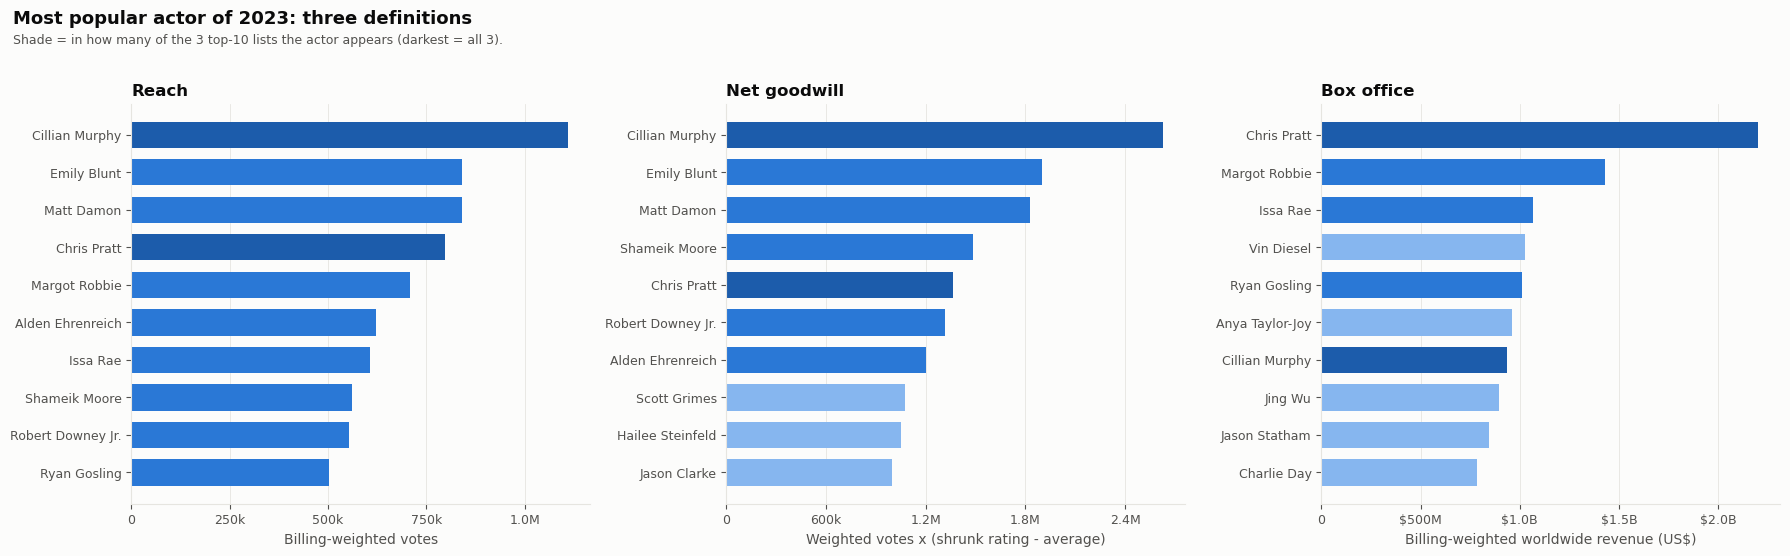

In [16]:
save(plots_v2.plot_actors_three_way(pop, box, year), f"03_actors_{year}")

**Slide talking point:** an actor in all three top-10 lists (darkest bars) is the safest casting bet: they draw crowds, the crowds like the films, and the films sell tickets.

## 3. Money: ROI and break-even

$$\text{ROI multiple} = \frac{\text{worldwide box office}}{\text{production budget}}, \qquad \text{profitable} \iff \text{ROI} \ge 2.5$$

**Why 2.5×?** It is the industry rule of thumb: theatres keep roughly half of ticket sales, and marketing (prints & advertising) costs about as much as production, so a film needs ~2.5× its production budget at the box office before the studio makes money. TMDB revenue is box office only (no streaming or home video), so this is conservative.

`above_breakeven_usd` = revenue − 2.5 × budget gives the same idea in dollars.

In [19]:
frame = hits.build_v2_frame(movies, tmdb, cfg, cpi)   # explained in section 4
fin = frame[frame["has_finance"]]
print(f"{len(frame):,} films in scope; {len(fin):,} have budget and revenue "
      f"({100 * len(fin) / len(frame):.0f}%).")
print(f"budget/revenue below are nominal US$; budget_real/revenue_real are in "
      f"{frame.attrs.get('dollar_basis')} (empty without a CPI file).")
fin[["budget", "revenue", "roi_multiple", "profitable"]].describe(percentiles=[.1, .5, .9]).T

INFO nextaaa.hits: v2 frame: 46,129 films (7,959 with budget + revenue)


46,129 films in scope; 7,959 have budget and revenue (17%).
budget/revenue below are nominal US$; budget_real/revenue_real are in 2023 US$ (empty without a CPI file).


,count,mean,std,min,10%,50%,90%,max
budget,"7,959.00","29,228,282.75","40,637,542.26","10,000.00","1,700,000.00","15,000,000.00","75,000,000.00","460,000,000.00"
revenue,"7,959.00","82,020,357.25","171,139,462.15","10,000.00","932,998.80","22,420,000.00","213,560,588.80","2,923,706,026.00"
roi_multiple,"7,959.00",5.22,51.13,0.00,0.17,1.82,7.93,"4,143.98"
profitable,"7,959.00",0.39,0.49,0.00,0.00,0.00,1.00,1.00


**Who has money data?** TMDB budgets are much more complete for big, recent, English-language films. So the money stage describes *studio-scale* filmmaking well and small independent films poorly. That is the right population for a AAA question, but say it out loud.

In [21]:
coverage = frame.groupby(frame["startYear"] // 10 * 10)["has_finance"].mean().mul(100).rename("% with money data")
coverage.to_frame().T

startYear,1950,1960,1970,1980,1990,2000,2010,2020
% with money data,0.00,0.00,11.44,23.93,30.41,27.49,18.95,5.09


## 4. Comparing eras: every axis relative to its own release year

A 1985 film has had 40 years to collect votes; $100M in 1980 is worth far more than in 2020; typical ratings and ROI drift by decade. So **every clustering axis** is turned into a **robust z-score against films released the same year**:

$$z = \frac{x - \text{median}_{\text{year}}}{\text{IQR}_{\text{year}} / 1.349}$$

plus a within-year **percentile** (0 to 100) for the slides. Years with too few films (budgets before ~1990) borrow neighbours: the window widens to ±1, ±2, … ±5 years until there are enough reference films.

| Axis | Raw measure | Stage |
|---|---|---|
| Quality | `averageRating` | audience |
| Reach | log₁₀ votes | audience |
| ROI | log₁₀ ROI multiple | commercial |
| Revenue | log₁₀ box office (2023 $ when CPI given) | commercial |

**Why this makes "by year" and "all time" one model:** after normalising, a film's score already means "how far above its own year". The **by-year** list reads the hits of each year; the **all-time** list ranks films by how completely they dominated their own year. No refitting per year, so thin years stay stable.

**Why z and not just percentiles?** z keeps the long right tail (true hits *are* far out), which DBSCAN, HDBSCAN and Isolation Forest need. Percentiles are used for display and for the hit score.

In [23]:
# Proof the normalisation works: raw medians drift by decade, z medians stay ~0.
check = frame.assign(decade=frame["startYear"] // 10 * 10)
raw = check.groupby("decade")[["averageRating", "log_votes"]].median()
rel = check.groupby("decade")[["z_quality", "z_reach", "z_roi", "z_revenue"]].median()
raw.join(rel)

,averageRating,log_votes,z_quality,z_reach,z_roi,z_revenue
decade,,,,,,
1950,6.80,3.40,0.00,0.00,NaN,NaN
1960,6.70,3.45,0.00,0.00,NaN,NaN
1970,6.60,3.45,0.00,0.00,0.00,0.00
1980,6.40,3.57,0.00,0.00,0.00,0.00
1990,6.50,3.70,0.00,0.00,0.00,0.00
2000,6.40,3.61,0.00,0.00,0.00,0.00
2010,6.20,3.52,0.00,0.00,0.00,0.00
2020,6.20,3.47,0.00,0.00,0.00,-0.00


## 5. The five methods (the same procedure runs on both stages)

Each method casts one vote, *hit* or *not*, per film.

**Partition methods** (every film gets a group):

1. **KMeans**: the film is in the cluster whose centre is furthest top-right. k is chosen with the **elbow** (Kneedle) and **silhouette**; the default is 4, the quadrant hypothesis.
2. **Median split**: above its year's median on both axes. No algorithm: the baseline every method must beat.

**Outlier methods** (is the film *unusual*?). A hit vote = unusual **and** in the top-right corner; unusual in the bottom-left is a spectacular flop, not a hit:

3. **DBSCAN** (Ester et al., 1996): outside the main dense mass. `eps` = knee of the k-distance plot.
4. **HDBSCAN** (Campello, Moulavi & Sander, 2013), via its outlier score **GLOSH** (Campello et al., 2015). HDBSCAN replaces DBSCAN's single `eps` with *every* `eps` at once:
   - core distance $\text{core}_k(a)$ = distance to the $k$-th neighbour; mutual reachability $d_{\text{mreach}}(a,b) = \max\{\text{core}_k(a), \text{core}_k(b), d(a,b)\}$;
   - a minimum spanning tree on $d_{\text{mreach}}$ gives a hierarchy of clusters as density $\lambda = 1/\varepsilon$ rises; clusters smaller than `min_cluster_size` are pruned; the most *stable* clusters are kept;
   - **GLOSH** $= 1 - \lambda_x / \lambda_{\max}(C)$: compare the density at which film $x$ drops out of its cluster $C$ with the highest density anywhere in $C$. 0 = in the dense heart, near 1 = far out. The **10% highest** count as unusual.
   - *Why GLOSH and not HDBSCAN's "noise" label?* On one continuous cloud of films, HDBSCAN either forces artificial splits or labels most films noise (40 to 95% on the synthetic test data). Check the `noise_pct` column in the method summary below on the real data. GLOSH is the authors' own outlier measure for exactly this purpose.
5. **Isolation Forest** (Liu, Ting & Zhou, 2008): random axis-aligned cuts isolate unusual points in fewer steps. With $h(x)$ the path length and $c(n) = 2H(n-1) - 2(n-1)/n$ the average path length of an unsuccessful search in a binary search tree, the score is $s(x) = 2^{-\mathbb{E}[h(x)]/c(n)}$ (near 1 = anomaly). It uses no distances or densities, so it fails differently from DBSCAN and HDBSCAN. The **10%** most anomalous count as unusual (the same strictness as GLOSH).

**Majority vote:** a film is a hit in a stage with **≥ 3 of 5** votes, and **mega** with **all 5**. Since outlier votes require the top-right corner, a 3-vote hit is roughly "clearly above its year on both axes, *and* at least one outlier method finds it exceptional".

## 6. Audience stage: quality × reach

Corners: **Hit** (high, high) · Hidden Gem (high quality, low reach) · Loser · Popular but Divisive (high reach, low quality).

In [26]:
aud = ensemble.run_stage(frame, ensemble.AUDIENCE, cfg)   # pass k=3 etc. to override KMeans
display(aud.method_summary)
print("Films by number of hit votes:", aud.vote_counts.to_dict())

INFO nextaaa.ensemble: Audience stage: 46,129 films
C:\Users\user\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\user\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\user\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\user\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\user\anaconda3\Lib\subprocess.py", line 1538, in _execute

,method,setting,flagged_unusual_pct,silhouette,clusters,noise_pct,hit_votes_pct
0,KMeans,"k = 4 (elbow 3, silhouette best 3)",NaN,0.35,4.00,NaN,21.07
1,Median split,above own year's median on both axes,NaN,NaN,4.00,NaN,29.44
2,DBSCAN,"eps = 0.145, min_samples = 25",2.30,0.51,1.00,2.30,0.80
3,HDBSCAN,GLOSH (hdbscan package); top 10% (min_cluster_...,10.00,0.41,1.00,31.78,4.28
4,Isolation Forest,"contamination = 0.1, 300 trees",10.00,NaN,NaN,NaN,4.33


Films by number of hit votes: {0: 30000, 1: 8663, 2: 5364, 3: 484, 4: 1292, 5: 326}


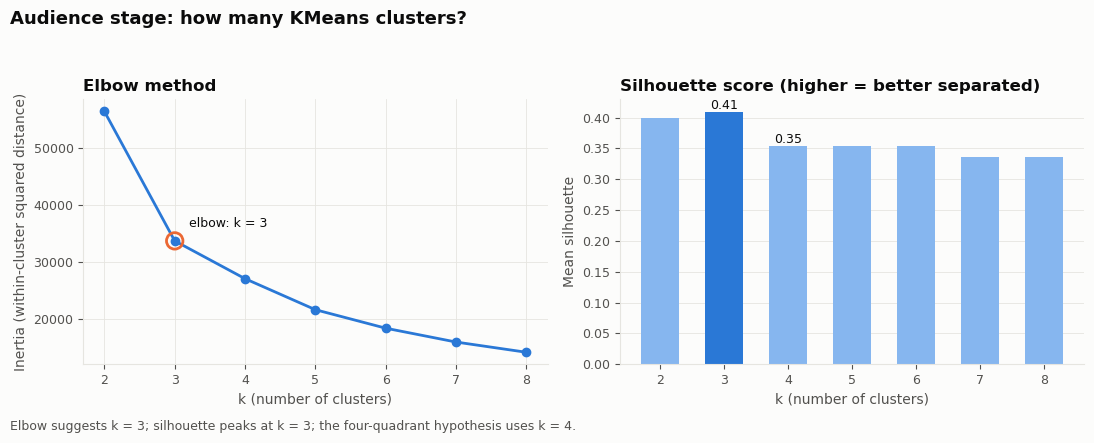

In [27]:
save(plots_v2.plot_stage_k(aud), "06_aud_elbow_silhouette")

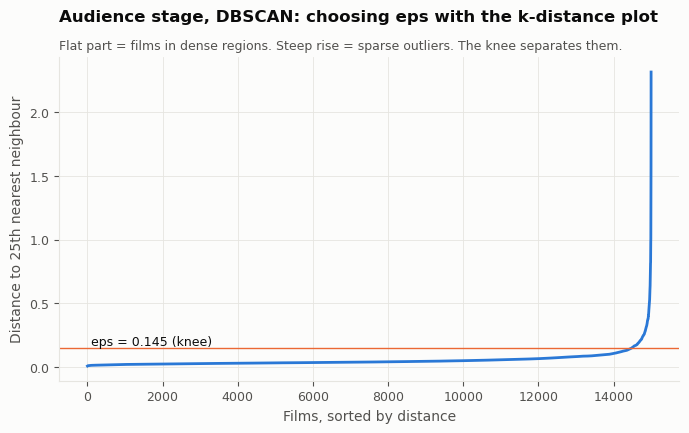

In [28]:
save(plots_v2.plot_stage_kdist(aud, cfg.dbscan_min_samples), "07_aud_k_distance")

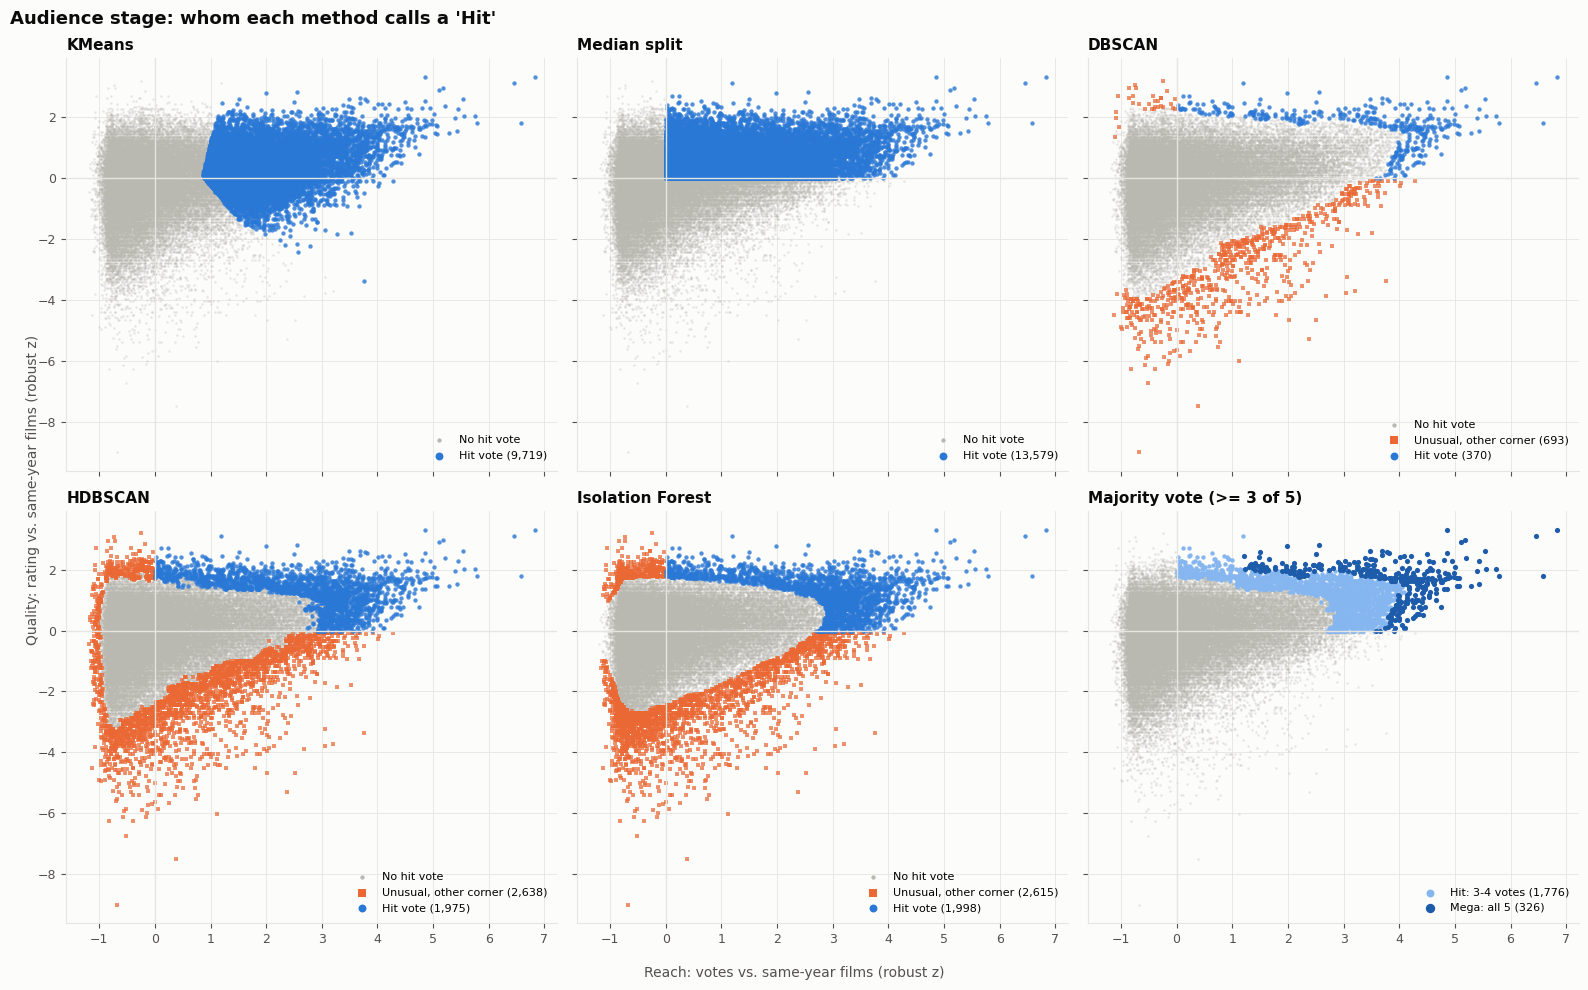

In [29]:
save(plots_v2.plot_method_maps(aud, cfg.hit_min_votes, cfg.mega_min_votes), "08_aud_method_maps")

**How to read the maps:** blue = that method's hit votes; orange = films the outlier methods find unusual but in another corner (flops, cult films). KMeans and the median split are generous (they draw a region); the three outlier methods are strict (they pick the edge of the cloud). The final panel keeps films where at least 3 agree.

## 7. Commercial stage: ROI × box office

Only films with budget and revenue. Corners: **Blockbuster** (high ROI, high box office) · Small-budget winner (high ROI, small box office) · Flop · Costly grosser (big box office, weak return).

INFO nextaaa.ensemble: Commercial stage: 7,959 films
INFO nextaaa.ensemble:   KMeans           hit votes  30.5%  unusual -
INFO nextaaa.ensemble:   Median split     hit votes  37.7%  unusual -
INFO nextaaa.ensemble:   DBSCAN           hit votes   0.6%  unusual 2.9%
INFO nextaaa.ensemble:   HDBSCAN          hit votes   1.7%  unusual 10.0%
INFO nextaaa.ensemble:   Isolation Forest hit votes   2.5%  unusual 10.0%


,method,setting,flagged_unusual_pct,silhouette,clusters,noise_pct,hit_votes_pct
0,KMeans,"k = 4 (elbow 4, silhouette best 2)",NaN,0.35,4.00,NaN,30.46
1,Median split,above own year's median on both axes,NaN,NaN,4.00,NaN,37.71
2,DBSCAN,"eps = 0.305, min_samples = 25",2.86,0.54,1.00,2.86,0.55
3,HDBSCAN,GLOSH (hdbscan package); top 10% (min_cluster_...,10.00,0.47,1.00,71.89,1.67
4,Isolation Forest,"contamination = 0.1, 300 trees",10.00,NaN,NaN,NaN,2.48


Films by number of hit votes: {0: 4827, 1: 839, 2: 2091, 3: 74, 4: 84, 5: 44}


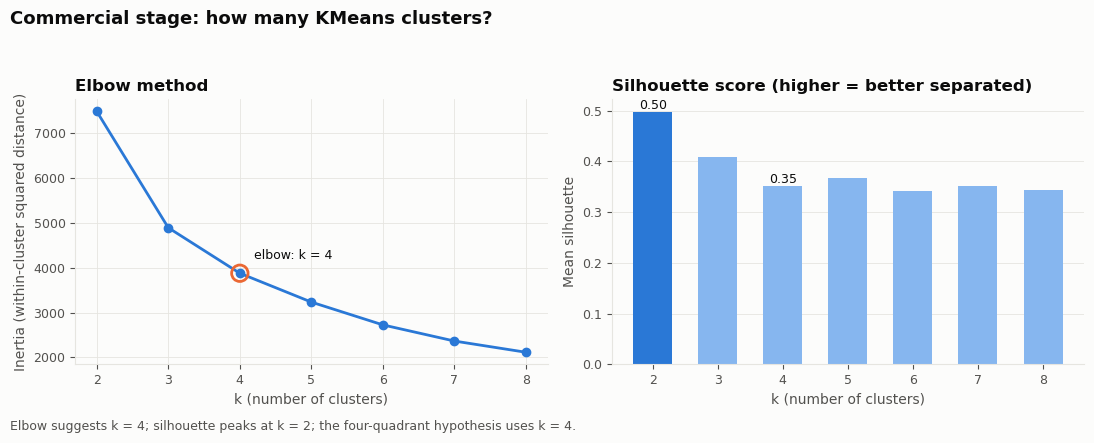

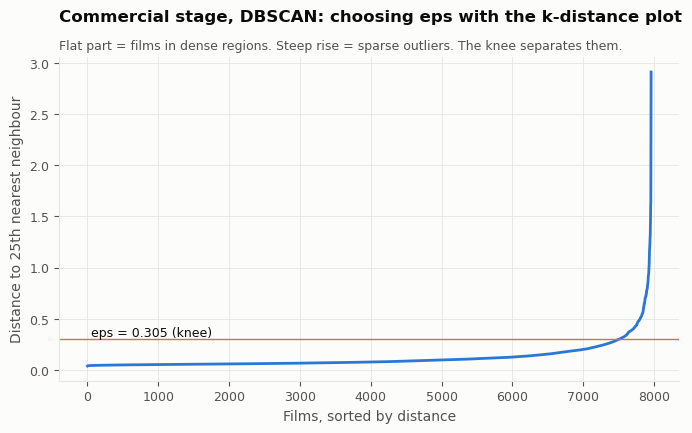

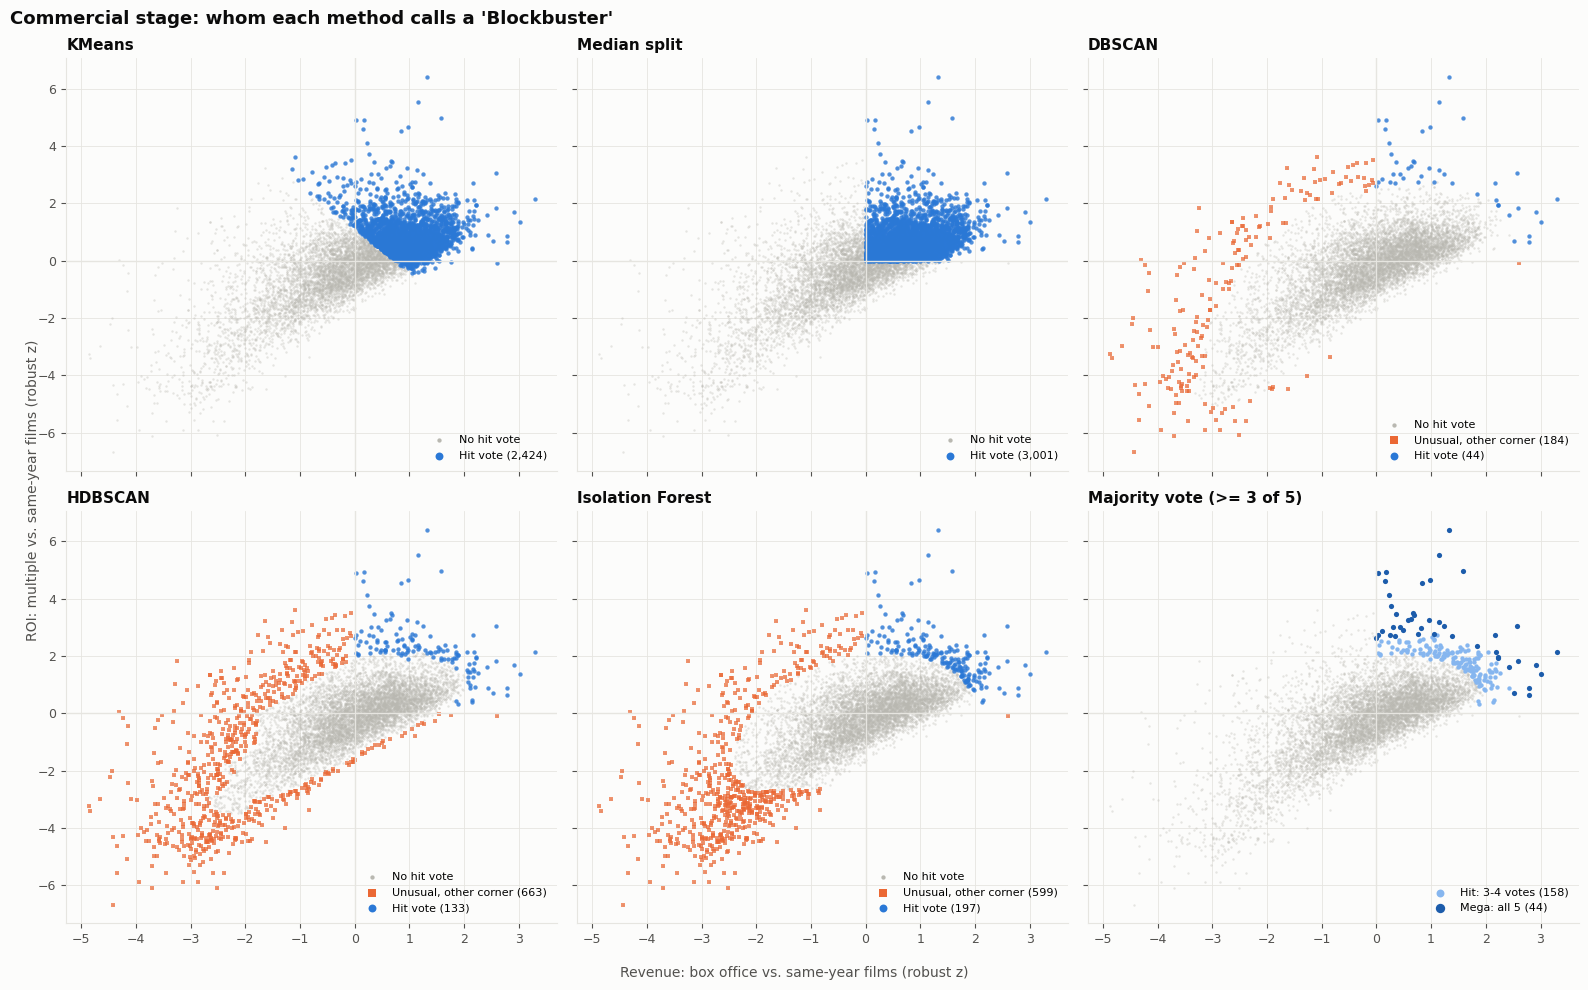

In [32]:
com = None
if frame["has_finance"].sum() >= 50:
    com = ensemble.run_stage(frame[frame["has_finance"]], ensemble.COMMERCIAL, cfg)
    display(com.method_summary)
    print("Films by number of hit votes:", com.vote_counts.to_dict())
    display(save(plots_v2.plot_stage_k(com), "09_com_elbow_silhouette"))
    display(save(plots_v2.plot_stage_kdist(com, cfg.dbscan_min_samples), "10_com_k_distance"))
    display(save(plots_v2.plot_method_maps(com, cfg.hit_min_votes, cfg.mega_min_votes), "11_com_method_maps"))
else:
    print("Not enough films with money data: commercial stage skipped.")

### Do the methods agree?
Cohen's kappa (agreement corrected for chance) rather than "% agree", because hits are rare: two methods that say "no" to everything would still agree 95% of the time.

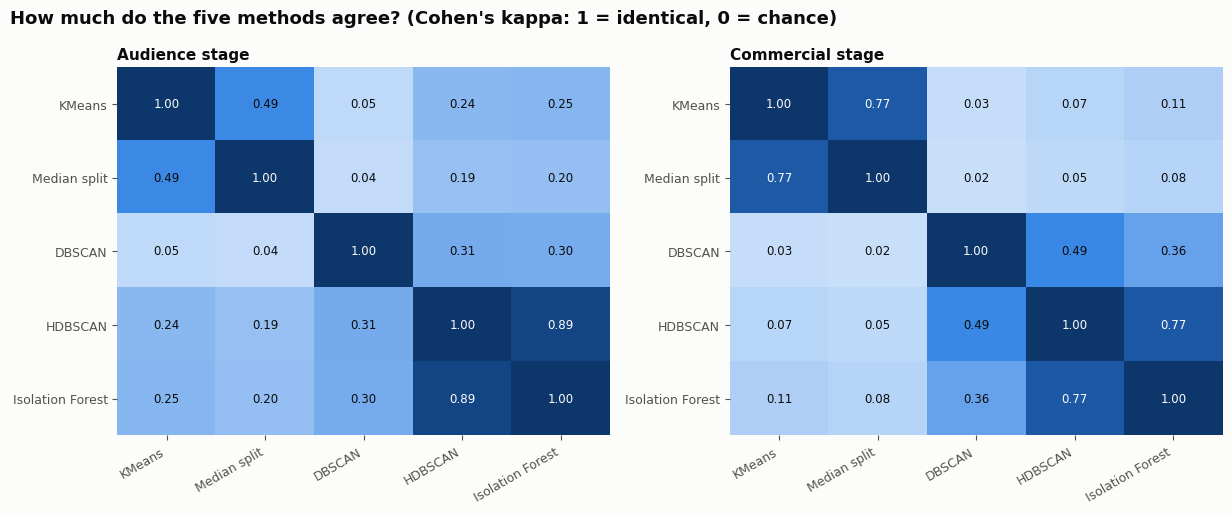

In [34]:
save(plots_v2.plot_agreement(aud, com), "12_method_agreement")

**What to say:** GLOSH and Isolation Forest agree closely even though they are built on different principles (density hierarchy vs. random partitioning), which is evidence that the outliers are real and not an artefact of one method. KMeans and the median split agree with each other but only moderately with the outlier methods: they answer "which region?", not "who is exceptional?". The vote combines both views.

## 8. The two-stage gate: from votes to verdicts

**Commercial hit** = commercial majority vote **and** ROI ≥ 2.5× (in a weak year, "above the year's median" can still mean losing money, so the absolute gate matters).

| | commercial hit | not a commercial hit |
|---|---|---|
| **audience hit** | **AAA hit** | Loved, unprofitable |
| **not an audience hit** | Profitable, not loved | Neither |

Films without money data keep their audience verdict. **AAA mega-hit** = unanimous in both stages.

**Why this metric suits a studio investing in a AAA title:** it requires all four things a franchise needs: people liked it (quality), many people saw it (reach), it sold tickets at scale (box office), and it paid back its cost (ROI). Each part is judged against the film's own year, so the bar is fair across eras.

In [37]:
labelled = hits.combine_stages(frame, aud.frame, com.frame if com else None, cfg)
display(hits.verdict_grid(labelled))
display(labelled["verdict"].value_counts().to_frame("films"))
display(labelled["aaa_tier"].replace("", np.nan).value_counts().to_frame("films"))

com_hit,Commercial hit,Not a commercial hit
aud_hit,,
Audience hit,113,1092
Not an audience hit,89,6665


,films
verdict,
No $ data,37273
Neither,6665
"Loved, unprofitable",1092
Audience hit (no $ data),897
AAA hit,113
"Profitable, not loved",89


,films
aaa_tier,
AAA hit,108
AAA mega-hit,5


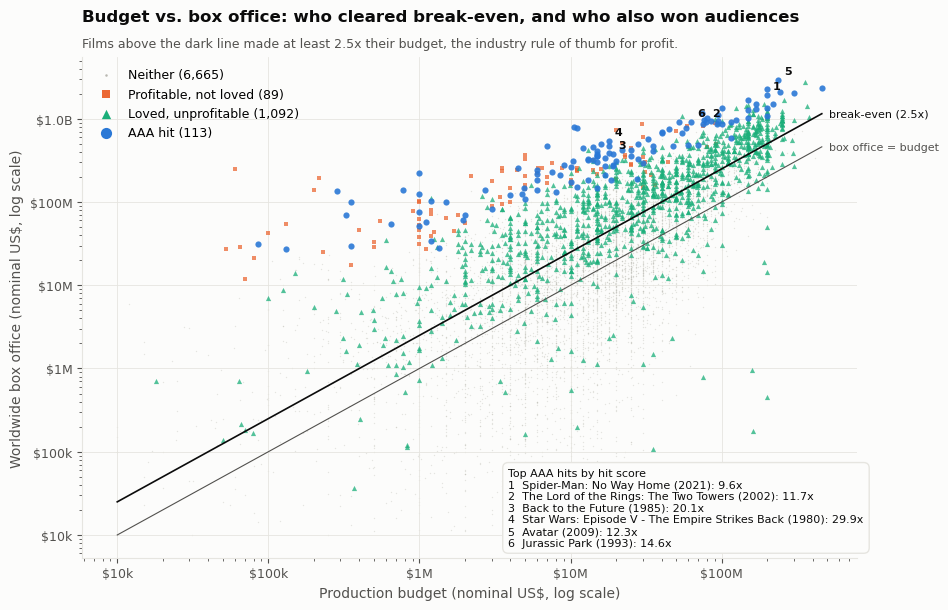

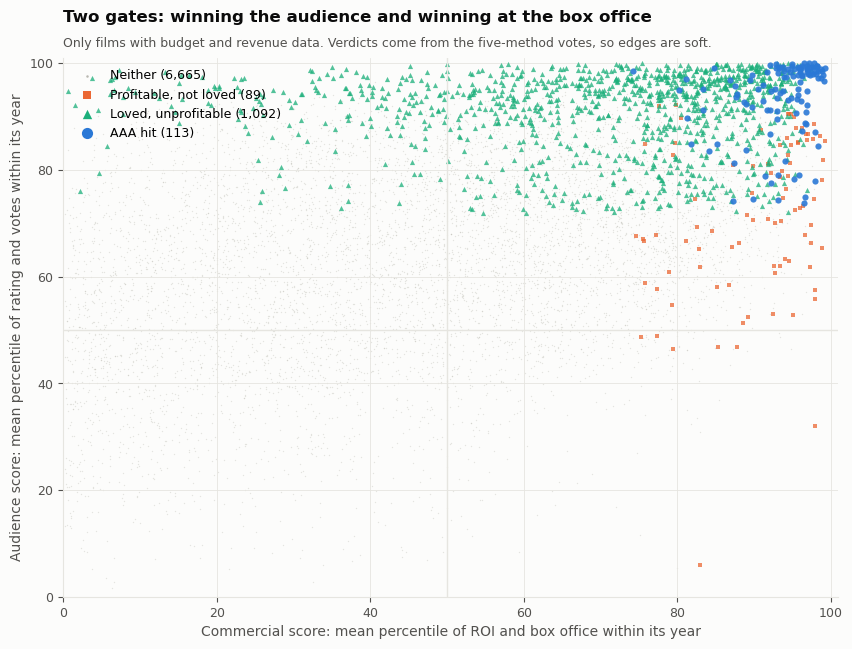

In [38]:
if com is not None:
    display(save(plots_v2.plot_budget_vs_revenue(labelled, cfg.breakeven_multiple), "04_budget_vs_revenue"))
    display(save(plots_v2.plot_verdict_map(labelled), "13_verdict_map"))

In [39]:
# Save the labels. The pickle keeps TMDB plot text (overview, tagline, keywords) for Part B.
keep = [c for c in labelled.columns if c not in ("overview", "tagline", "keywords")]
labelled[keep].to_csv(TAB / "hit_labels_v2.csv", index=False)
labelled.to_pickle(paths.cache_dir / "hit_labels_v2.pkl")

### Does spending more make a hit more likely?

,films,median_budget,median_roi,profitable_pct,lost_money_pct,aaa_hit_pct
budget_tier,,,,,,
< $10M,2188,"4,246,378.75",2.00,44.29,34.55,1.14
$10-40M,2859,"22,222,508.55",1.58,36.41,37.92,0.87
$40-100M,1913,"59,253,172.69",1.68,34.81,34.55,1.78
AAA-scale ($100M+),999,"148,642,803.08",2.26,44.64,18.92,2.90


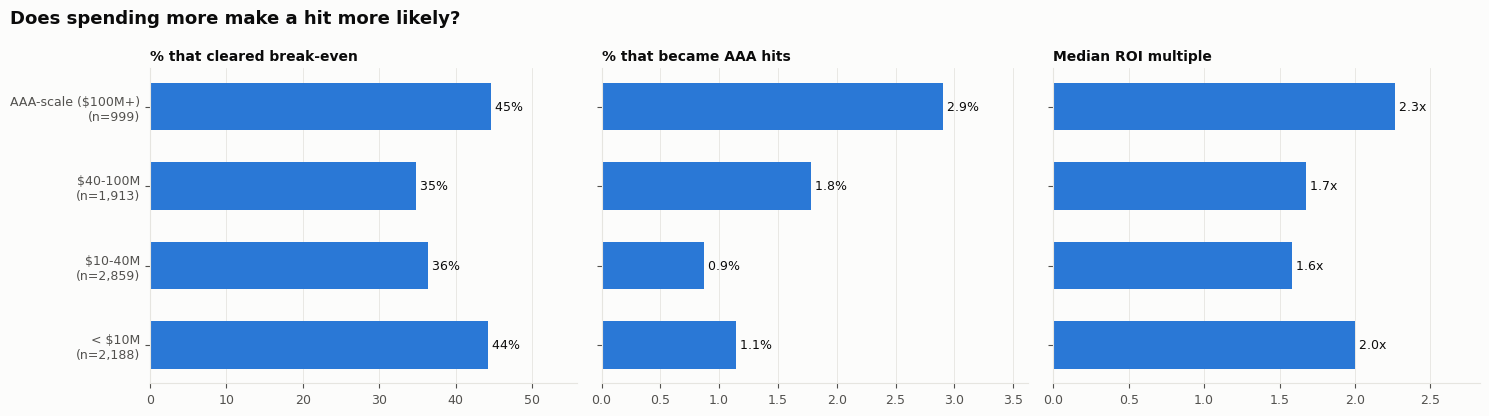

In [41]:
if com is not None:
    tiers = finance.budget_tier_economics(labelled, "verdict")
    display(tiers)
    display(save(plots_v2.plot_budget_tiers(tiers), "05_budget_tiers"))

**How to read it:** if the AAA-hit rate rises with budget while the median ROI falls, big budgets buy a *better chance* of a hit, at a *lower return* per dollar. That is the trade-off a AAA greenlight accepts.

## 9. Hits by year

The **hit of the year** is the AAA hit with the highest **hit score** (the mean of its four within-year percentiles). Years with no AAA hit (or no money data) show their top audience hit instead.

In [44]:
yearly = hits.yearly_summary(labelled)
yearly.to_csv(TAB / "yearly_summary.csv", index=False)
yearly.tail(15)

,year,films,audience_hits,films_with_money,profitable_pct,aaa_hits,aaa_hit_pct_of_money_films,hit_of_the_year,hit_of_the_year_score,top_audience_hit
61,2011,1173,42,288.00,42.01,0.00,0.00,NaN,NaN,The Intouchables
62,2012,1271,78,261.00,40.61,2.00,0.77,The Avengers,96.24,Django Unchained
63,2013,1364,75,304.00,37.50,3.00,0.99,The Conjuring,95.41,The Wolf of Wall Street
64,2014,1464,79,286.00,43.71,0.00,0.00,NaN,NaN,Interstellar
65,2015,1466,87,272.00,44.12,3.00,1.10,Star Wars: Episode VII - The Force Awakens,96.27,Mad Max: Fury Road
66,2016,1570,101,313.00,43.13,6.00,1.92,Deadpool,97.32,Your Name.
67,2017,1657,89,275.00,42.91,6.00,2.18,Get Out,95.59,Coco
68,2018,1702,83,234.00,44.44,8.00,3.42,Bohemian Rhapsody,97.46,Avengers: Infinity War
69,2019,1730,87,224.00,41.96,0.00,0.00,NaN,NaN,Parasite
70,2020,1310,39,106.00,25.47,1.00,0.94,Demon Slayer: Kimetsu no Yaiba - The Movie: Mu...,98.44,The Father


,rank_in_year,startYear,primaryTitle,genres,hit_score,pct_quality,pct_reach,pct_roi,pct_revenue,averageRating,numVotes,budget,revenue,roi_multiple,budget_real,revenue_real,aaa_tier,tconst
99,1,2021,Spider-Man: No Way Home,"Action,Adventure,Fantasy",99.13,98.10,99.90,98.88,99.63,8.10,1084482,"200,000,000.00","1,921,847,111.00",9.61,"224,895,123.48","2,161,070,216.65",AAA hit,tt10872600
100,1,2022,Top Gun: Maverick,"Action,Drama",97.09,97.88,99.92,91.67,98.91,8.20,910995,"170,000,000.00","1,488,732,821.00",8.76,"177,015,836.75","1,550,172,270.58",AAA hit,tt1745960
101,2,2022,Avatar: The Way of Water,"Action,Adventure,Fantasy",92.82,90.32,99.80,81.52,99.64,7.50,650861,"460,000,000.00","2,320,250,281.00",5.04,"478,984,028.84","2,416,006,146.76",AAA hit,tt1630029
102,3,2022,Kantara,"Action,Adventure,Drama",89.13,97.40,96.81,98.19,64.13,8.10,119071,"1,934,000.00","60,447,800.00",31.26,"2,013,815.46","62,942,458.21",AAA hit,tt15327088
103,4,2022,Minions: The Rise of Gru,"Adventure,Animation,Comedy",86.75,59.88,96.53,93.84,96.74,6.50,110045,"85,000,000.00","939,628,210.00",11.05,"88,507,918.37","978,406,316.60",AAA hit,tt5113044
104,1,2023,The Super Mario Bros. Movie,"Adventure,Animation,Comedy",92.65,77.86,99.50,94.94,98.31,7.00,303998,"100,000,000.00","1,355,725,263.00",13.56,"100,000,000.00","1,355,725,263.00",AAA hit,tt6718170


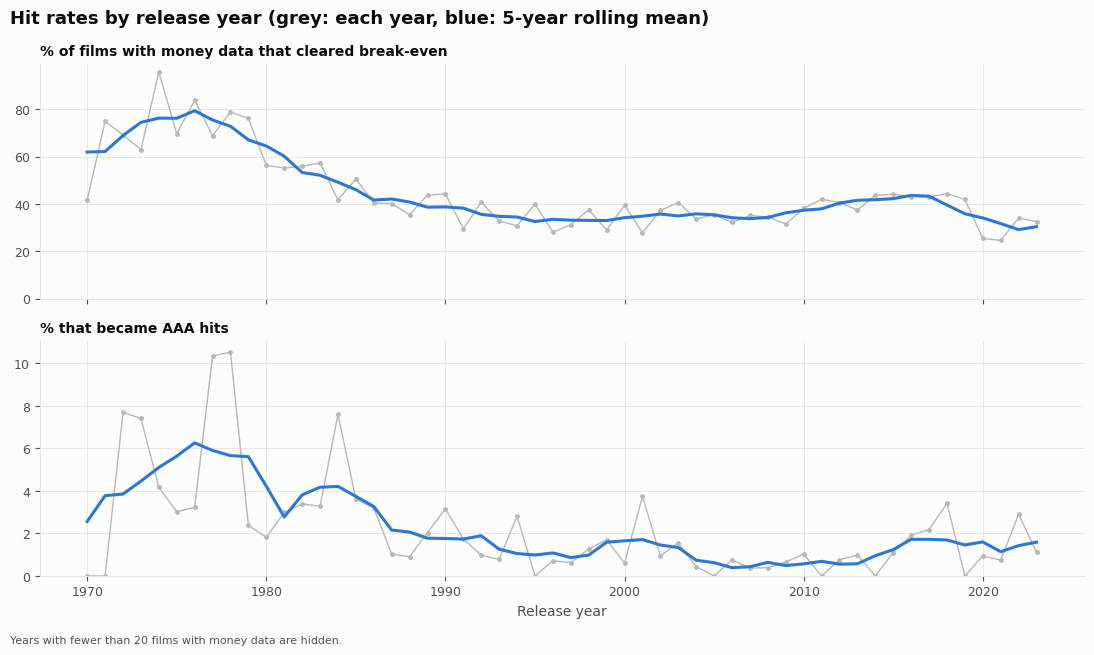

In [45]:
if com is not None:
    by_year = hits.hits_by_year(labelled, cfg.top_n_per_year)
    by_year.to_csv(TAB / "aaa_hits_by_year.csv", index=False)
    display(by_year[by_year["startYear"] >= cfg.max_year - 4])
    display(save(plots_v2.plot_hits_per_year(yearly), "14_hit_rates_by_year"))

**Trend question for the deck:** is it getting harder to make a hit? Read the blue (5-year rolling) lines: a falling break-even rate with a flat AAA rate means more films lose money while the very top stays as reachable as before.

## 10. All-time hits

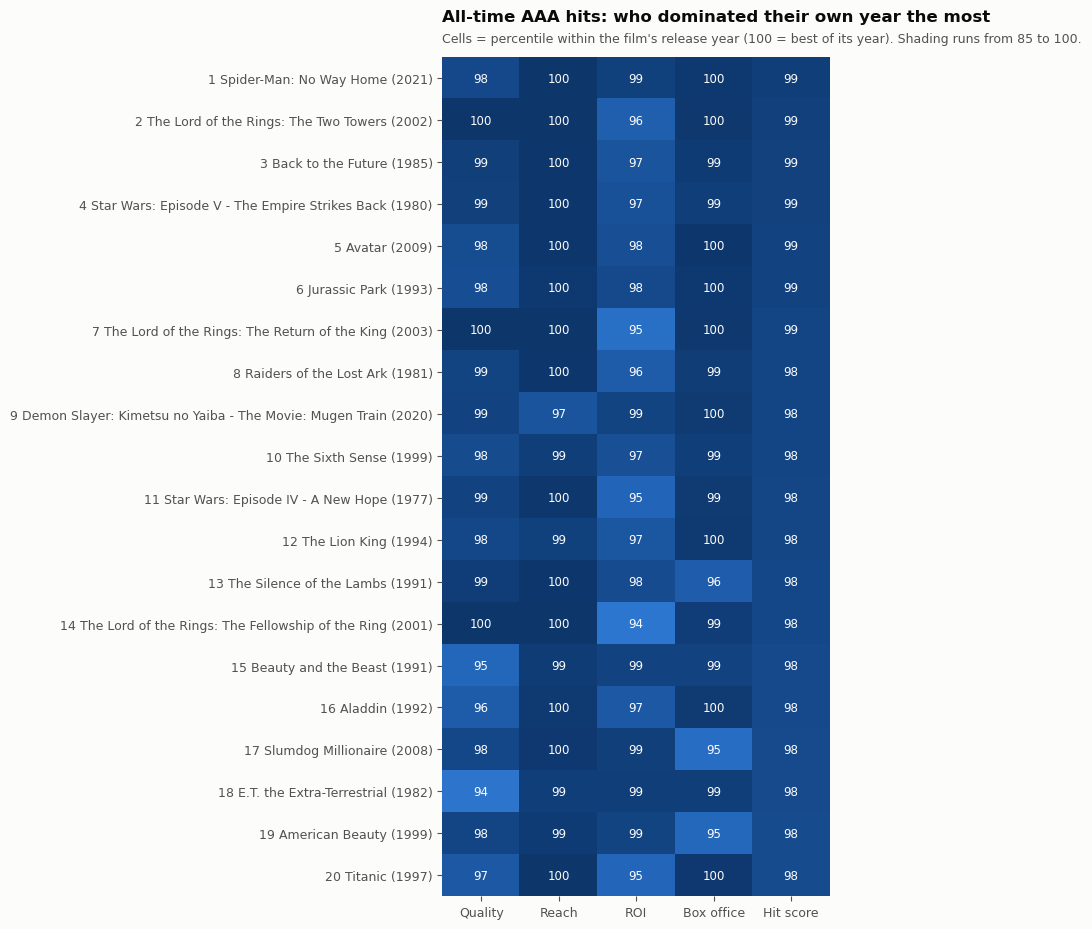

Cross-check: biggest box office in base-year dollars


,startYear,primaryTitle,revenue_real,roi_multiple,verdict
0,1997,Titanic,"4,297,754,626.67",11.32,AAA hit
1,2009,Avatar,"4,151,951,069.48",12.34,AAA hit
2,1977,Star Wars: Episode IV - A New Hope,"3,897,708,533.30",70.49,AAA hit
3,2019,Avengers: Endgame,"3,337,217,988.87",7.87,"Loved, unprofitable"
4,1973,The Exorcist,"3,027,521,079.21",36.78,AAA hit
5,1975,Jaws,"2,664,363,791.16",67.24,AAA hit
6,2015,Star Wars: Episode VII - The Force Awakens,"2,659,026,538.43",8.44,AAA hit
7,1982,E.T. the Extra-Terrestrial,"2,502,958,909.67",75.52,AAA hit
8,2018,Avengers: Infinity War,"2,490,554,619.30",6.84,AAA hit
9,2022,Avatar: The Way of Water,"2,416,006,146.76",5.04,AAA hit


In [48]:
if com is not None:
    all_time = hits.all_time_hits(labelled, cfg.top_n_all_time)
    all_time.to_csv(TAB / "aaa_hits_all_time.csv", index=False)
    display(save(plots_v2.plot_all_time_heatmap(all_time), "15_all_time_aaa_hits"))
    real = hits.all_time_by_real_revenue(labelled, 10)   # needs CPI
    if real is not None:
        print("Cross-check: biggest box office in base-year dollars")
        display(real[["startYear", "primaryTitle", "revenue_real", "roi_multiple", "verdict"]])

In [49]:
# Audience-only all-time list (includes films without money data).
hits.audience_all_time(labelled, 15)

,startYear,primaryTitle,genres,audience_score,pct_quality,pct_reach,averageRating,numVotes,verdict
0,2008,The Dark Knight,"Crime,Thriller",99.95,99.95,99.95,9.10,3243979,"Loved, unprofitable"
1,2010,Inception,"Adventure,Sci-Fi,Thriller",99.93,99.91,99.95,8.80,2883775,"Loved, unprofitable"
2,2003,The Lord of the Rings: The Return of the King,"Adventure,Drama,Fantasy",99.93,99.93,99.93,9.00,2204006,AAA hit
3,2002,The Lord of the Rings: The Two Towers,"Adventure,Drama,Fantasy",99.93,99.93,99.93,8.80,1993442,AAA hit
4,2006,The Prestige,"Drama,Mystery,Sci-Fi",99.92,99.90,99.95,8.50,1637112,"Loved, unprofitable"
5,2001,The Lord of the Rings: The Fellowship of the Ring,"Adventure,Drama,Fantasy",99.92,99.92,99.92,8.90,2248098,AAA hit
6,2014,Interstellar,"Adventure,Sci-Fi",99.91,99.86,99.97,8.70,2626146,"Loved, unprofitable"
7,2012,The Dark Knight Rises,"Crime,Thriller",99.88,99.80,99.96,8.40,2035214,"Loved, unprofitable"
8,2012,Django Unchained,"Drama,Western",99.88,99.88,99.88,8.50,1923038,"Loved, unprofitable"
9,2006,The Departed,"Crime,Drama,Thriller",99.87,99.90,99.85,8.50,1587144,"Loved, unprofitable"


**Slide talking point:** the all-time list is not "biggest box office ever" (inflation and market growth make that a list of recent films). It is **who dominated their own year most completely** on quality, reach, ROI and box office at once. The real-dollar list is the familiar cross-check.

## 11. What to make next? Genre economics (recent years)

Genre rates over the last `genre_recent_years` (default 15). A film tagged "Action,Sci-Fi" counts in both.

,films,median_budget,median_roi,profitable_pct,audience_hit_pct,aaa_hit_pct
genre,,,,,,
Animation,215,"76,170,074.58",2.44,48.84,27.91,4.65
Sci-Fi,203,"51,426,286.94",2.21,42.86,44.33,3.94
Horror,334,"8,868,881.05",2.46,49.40,18.86,2.99
Adventure,697,"70,711,144.54",2.19,44.91,31.56,2.58
Music,78,"14,256,740.16",1.91,44.87,19.23,2.56
Mystery,323,"11,918,635.67",1.80,43.03,23.22,2.17
Action,960,"38,730,617.13",1.93,38.54,28.54,1.56
Thriller,502,"13,529,449.42",2.13,43.23,26.49,1.20
Fantasy,217,"32,842,212.47",1.63,35.02,23.96,0.92


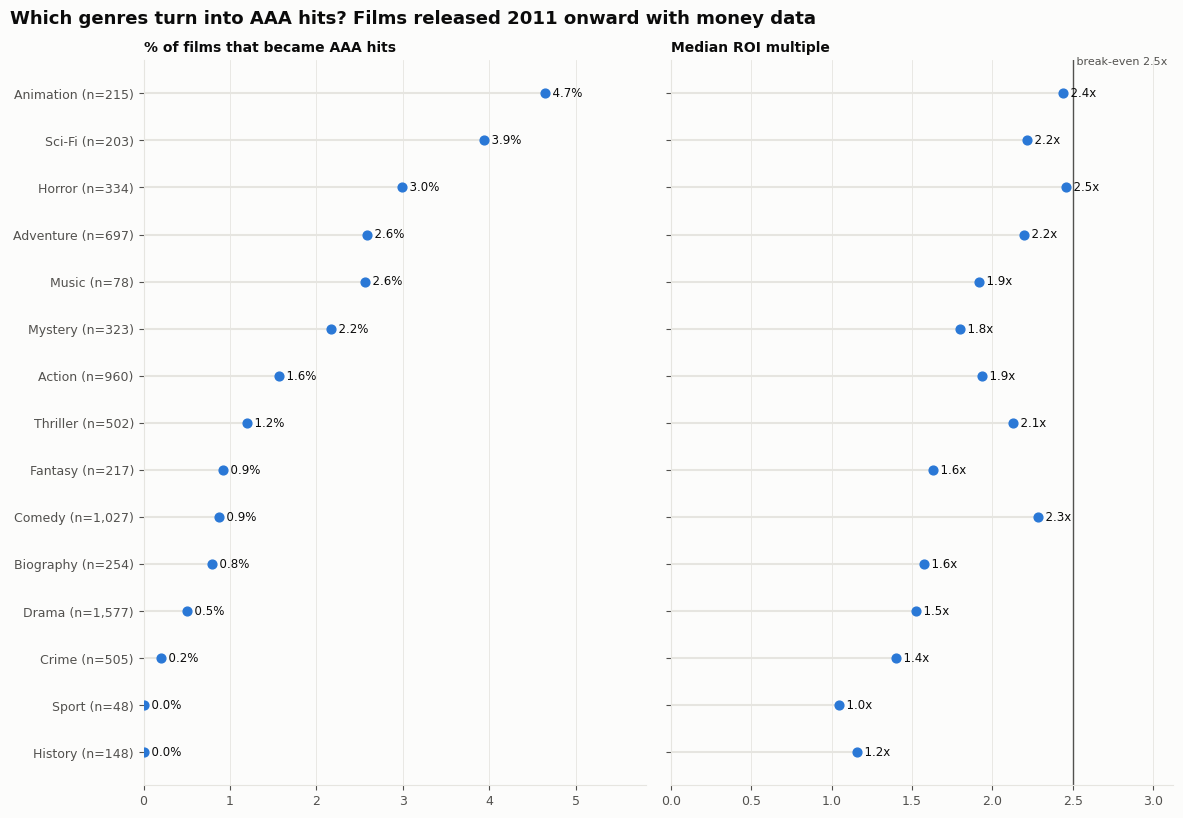

In [52]:
if com is not None:
    since = cfg.max_year - cfg.genre_recent_years + 1
    genres = hits.genre_economics(labelled, since)
    genres.to_csv(TAB / "genre_economics.csv")
    display(genres)
    display(save(plots_v2.plot_genre_economics(genres, cfg.breakeven_multiple, since), "16_genre_economics"))

**How to read it:** a genre with a high AAA-hit rate is a strong AAA candidate; a genre with a high *median ROI* but a low AAA-hit rate (horror is the classic case) makes money reliably at small budgets but rarely becomes a tentpole. This table feeds Part B's concept generator directly.

## 12. Trends in audience preferences (from v1)

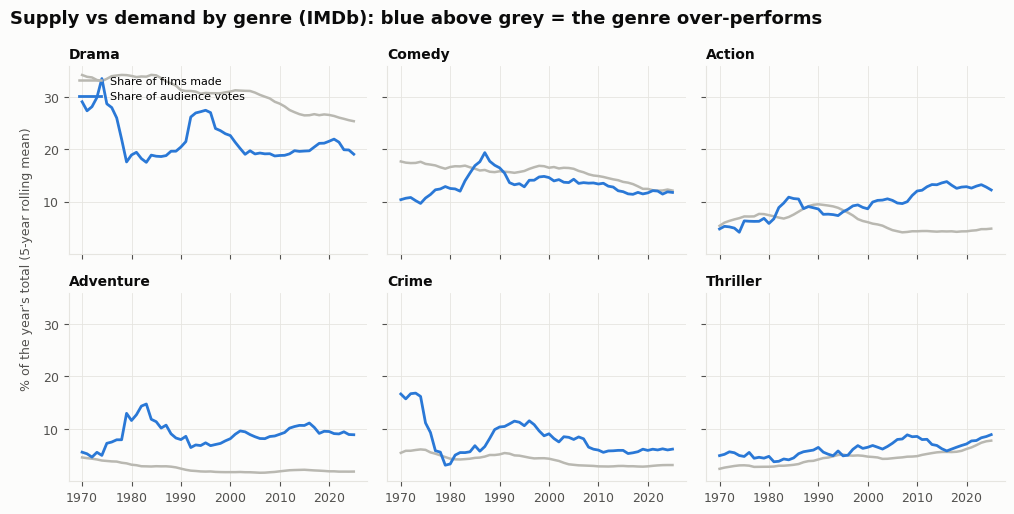

In [54]:
imdb_tr = trends.imdb_genre_trends(movies, cfg)
display(save(plots.plot_imdb_genre_trends(imdb_tr), "17_imdb_genre_trends"))

In [55]:
ml = movielens.load_movielens(paths)
if ml is not None:
    yearly_ml = trends.movielens_yearly_summary(ml, cfg.movielens_min_ratings_per_year)
    display(save(plots.plot_movielens_yearly(yearly_ml), "18_movielens_yearly"))
    # Is "Popular but Divisive" really divisive? (individual MovieLens ratings)
    spread = trends.rating_spread_by_cluster(ml, labelled, "aud_kmeans", cfg.movielens_min_ratings_for_std)
    if len(spread):
        display(save(plots.plot_divisiveness(spread, "aud_kmeans"), "19_divisiveness_check"))

INFO nextaaa._cache: Building ml_ratings (this can take a few minutes the first time)...


ValueError: invalid literal for int() with base 10: '2005-04-02 23:53:47'

## 13. Summary and hand-off to Part B

- **2023:** highest-rated film by shrunk rating (with its money); most popular actor under three definitions.
- **Hit metric:** a two-stage gate, audience × commercial, each decided by a five-method vote (KMeans, median split, DBSCAN, HDBSCAN/GLOSH, Isolation Forest) on year-relative axes, with an absolute 2.5× break-even.
- **Lists:** hits by year, all-time hits (dominance of their own year), plus budget-tier and genre economics.
- **Saved for Part B:** `data/cache/hit_labels_v2.pkl`, every film with its verdict, scores, money, and **TMDB plot text** (so Part B's LLM concept generator no longer needs the Wikipedia plots dataset).

**Next (Part B):** generate → score → refine. Azure OpenAI proposes concepts; a separate scorer, trained on these verdicts with **pre-release features only** (genre, runtime, budget tier, director and cast track record, franchise flag), estimates each concept's chance of becoming a AAA hit.